# Separate pixel positions, map coordinates and runtime compatibility

**Learning question:** Where is a pixel centre in a projected raster, and why does a correct coordinate not establish runtime compatibility?

Thirteen complete TerrIO reading/editing copies preserve real Natural Earth countries, original SVG chapter cards, helpers and synthetic raster/vector/point-cloud workflows.

This introductory calculation is an original **synthetic** teaching exercise. Full source lessons and their actual data status are separately described below.


## Predict before running

For a north-up raster with no rotation, a pixel centre lies half a pixel beyond its zero-based column and row origin. A negative vertical pixel size means row indices grow southward. Projected metres differ from longitude/latitude degrees; never attach an invented WGS84 CRS to projected coordinates.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Synthetic projected pixel centre (metres): (500315.0, 4399385.0)
Zero-based array index (row, column): (20, 10)
Idealized Mercator local length scale | map distance / ground distance: {'0 degrees': 1.0, '30 degrees': 1.155, '60 degrees': 2.0}


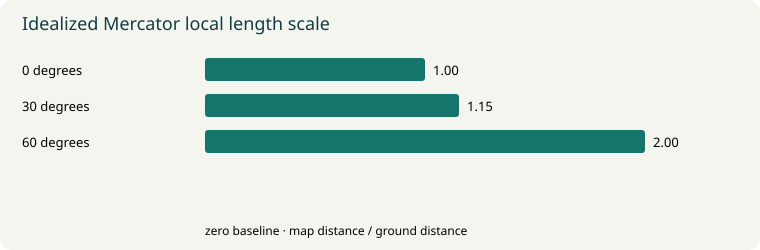

In [2]:
from math import cos, radians
origin_x, origin_y = 500000, 4400000
pixel_width, pixel_height = 30, -30
column, row = 10, 20
centre_x = origin_x+(column+0.5)*pixel_width
centre_y = origin_y+(row+0.5)*pixel_height
scale = {str(lat)+' degrees':1/cos(radians(lat)) for lat in [0,30,60]}
print('Synthetic projected pixel centre (metres):', (centre_x,centre_y))
print('Zero-based array index (row, column):', (row,column))
assert (centre_x,centre_y) == (500315,4399385)
bars(scale, 'Idealized Mercator local length scale', 'map distance / ground distance')


## Interpret the result

Column 10, row 20 has centre (500315, 4399385) projected metres. This coordinate is synthetic and has no declared real CRS. Ideal spherical Mercator scale is 1 at the equator and 2 at 60 degrees: equal map lengths can represent different ground lengths. This stdlib exercise runs in Atlas independently of the TerrIO wasm package.

## Change one thing

Double the pixel size while keeping the origin fixed; predict the centre displacement. Then change the row to zero and explain the half-pixel offset. Before transferring an actual vector/raster export, keep CRS, affine transform, NoData, units and source receipt together; reproject with a verified tool before using the WGS84 GIS workbench.


## Source course and scientific boundaries

All 13 source notebooks and terrio_lab.py, countries.geojson, sources.json, chapter SVGs, chapter registry and attribution/resources guides are retained. The imported TerrIO notebooks are reading/editing copies in Atlas: TerrIO 0.9.0 has a pyemscripten_2025_0 wasm ABI for Pyodide 0.29. The source pins kernel 0.8.0b0, whose default is Pyodide 0.29.4; Atlas uses Pyodide 314. Run TerrIO in the matched [source Lab](https://jltobias.github.io/JupyterLite-terrio/lite/lab/index.html?path=01-first-contact.ipynb). Do not install its incompatible wheel or downgrade Atlas. Source Plotly 6.3.1/xarray 2025.10.1, CDN and WebGL requirements remain explicit; static and numerical alternatives are available. Native HTTP range I/O and specialized drivers remain optional native continuations.

[Complete local course guide](../../courses/terrio/index.ipynb) · [Notebook library](../../notebook-library.ipynb)


## Sources, attribution and limits

[Reviewed source README](https://github.com/jltobias/JupyterLite-terrio/blob/18574d4e7a8dabb99d3db65b20c6180185578482/README.md) · [Source repository](https://github.com/jltobias/JupyterLite-terrio)

Original code MIT; original teaching prose/synthetic data/13 chapter SVGs CC0. No TerrIO wheel is redistributed. Keep TerrIO/dependency/EPSG/IOGP notices separate. The sole bundled real geographic dataset is Natural Earth countries v5.1.2, 177 generalized features, public domain: Made with Natural Earth; Patterson, Kelso and contributors. It is not authoritative boundary evidence. All terrain, reflectance, stations, points and cube examples are explicitly synthetic. Cite Wu, Fitzgerald & Morales Sanchez (2026), TerrIO software concept DOI 10.5281/zenodo.23642204, separately from software version 0.9.0 and this course commit; the course has no assigned DOI.

- [Read source Book](https://jltobias.github.io/JupyterLite-terrio/book/intro.html) — Source-route reviewed; HTTP entry not freshly checked
- [Run matched TerrIO source Lab](https://jltobias.github.io/JupyterLite-terrio/lite/lab/index.html?path=01-first-contact.ipynb) — Source-route reviewed; HTTP entry not freshly checked
- [Open source portal](https://jltobias.github.io/JupyterLite-terrio/) — Source-route reviewed; HTTP entry not freshly checked
- [Explore TerrIO 2D maps](https://jltobias.github.io/JupyterLite-terrio/maps/2d.html) — Source-route reviewed; HTTP entry not freshly checked
- [Explore TerrIO 3D maps](https://jltobias.github.io/JupyterLite-terrio/maps/3d.html) — Source-route reviewed; HTTP entry not freshly checked
- [Explore TerrIO scene and globe](https://jltobias.github.io/JupyterLite-terrio/maps/scenes.html) — Source-route reviewed; HTTP entry not freshly checked

[Central references](../../references.ipynb)


## Browser GIS pathway

**Geographic question:** Which CRS and provenance checks must accompany a TerrIO export before a geographic browser handoff?

**Data readiness (B + O; matched source runtime):** Natural Earth countries v5.1.2 are real public-domain generalized geography; remaining raster/point/cube fixtures are synthetic. Atlas copies are reference-only because TerrIO 0.9.0 requires Pyodide 0.29 rather than Atlas 314.

**Start from the chapter evidence:** [coordinate checks](../../courses/terrio/02-coordinates.ipynb) · [country vectors](../../courses/terrio/03-vectors-2d-maps.ipynb) · [interoperability](../../courses/terrio/12-interoperability.ipynb) · [Natural Earth sources](https://github.com/jltobias/JupyterLite-Learning-Atlas/blob/main/content/courses/terrio/data/sources.json) (`courses/terrio/data/sources.json`)

- **[RustGIS Web](https://web.rustgis.app/):** For a direct geography exercise, use an attributed bounded copy of the bundled WGS84 Natural Earth countries. For TerrIO-created exports, run the matched source Lab and verify the reopened file/CRS before import.
- **[GeoLibre Web](https://web.geolibre.app/):** Import the same reviewed country subset and compare ADMIN-name multisets, selected count and attribution. Keep projected pixel coordinates out of WGS84 exports until a verified transformation.

**Handoff:** Use the [GIS workbench](../../gis-workbench.ipynb) to validate/export an attributed WGS84 layer. Download the GeoJSON, method record and review prompt from `exports/`, then import through the chosen app’s file picker. Compare `_atlas_source_id` (or source `GEOID`) with the original IDs; app-generated internal IDs may differ. Return changed results by explicit upload. Apps and the notebook share no files or kernel state. Practice-only Census data remain Fresno 2020, never this subject’s observations.

**Optional AI prompt (approved subject evidence only):** “Audit the supplied CRS, transform, NoData, ADMIN names and separate synthetic/real status; state what cannot be inferred from generalized boundaries. Cite supplied feature IDs/fields, separate observations from assumptions, abstain when evidence is missing, and propose one falsifiable check.” For the common practice package, use its generated schema/summary prompt instead. A human-written answer completes the same task.

**GeoAI opportunity:** Future raster classification requires independent imagery/labels and spatial holdouts; format conversion, NDVI thresholds and terrain styling are not fitting. Any later fitted exercise must name target/features and spatial/temporal support, reserve a spatial/temporal holdout, inspect leakage and uncertainty, and state evidence that would disprove the interpretation. Styling, thresholds, schema checks and chat alone are not model fitting.

**Human evidence check:** Retain Made with Natural Earth, version 5.1.2, 177-feature source count, subset IDs, CRS and TerrIO 0.29 ABI source-runtime boundary. Ask the intended reader which decision the map supports; change one legend, filter or annotation, then recheck interpretation against the same IDs and values.

**Continue:** [cross-tool guide and optional Ollama setup](../../browser-gis.ipynb) · [RustGIS assistance](../../courses/rustgis/07_ollama_assistance.ipynb) · [GeoLibre setup](../../courses/geolibre-geoai/18_ollama_geolibre_setup.ipynb) · [chat-to-map](../../courses/geolibre-geoai/19_ollama_chat_to_map.ipynb) · [evidence review](../../courses/geolibre-geoai/20_ollama_evidence_review.ipynb). AI is optional; no service or model is called by this pathway.
